# Heat Notebook
12 easy to following steps and repeatable with any city or area

## 1. Setup: Imports / Initializing

In [62]:
import geemap
import ee
import geopandas as gpd
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Uncomment and run Authenticate once then you don't need it anymore
#ee.Authenticate()
ee.Initialize(project = "dfw-urbanheat")

## 2. Parameters
ONLY change this section

In [3]:
#STUDY AREA
STATE_FIPS = '48'                   #State
COUNTY_FIPS = ['113', '439']        #County codes
MAP_CENTER = (32.8, -96.9)          #Middle of DFW
MAP_ZOOM = 10                       #Zoom

#TIME PERIOD
START_DATE = "2020-01-01"           #Date Start
END_DATE = "2024-12-31"             #Date End
START_MONTH = 6                     #Month Start
END_MONTH = 8                       #Month End
#--------------------Don't--Change-----------------------------------
LANDSAT8 = "LANDSAT/LC08/C02/T1_L2" #Landsat 8 (8 & 9 are combined)
LANDSAT9 = "LANDSAT/LC09/C02/T1_L2" #Landsat 9 (8 & 9 are combined)
#--------------------------------------------------------------------

#IMAGE FILTERING
MAX_CLOUD_COVER = 20                #Max cloud cover allowed (%)

#PROCESSING 
SCALE = 30                          #Landsat resolution

#ANALYSIS
EXPOSURE_WEIGHT = 0.33              #exposure = median temp + (1 - NDVI)
SENSITIVITY_WEIGHT = 0.33           #sensitivity = pct no vehicle + distance from station
ADAPTABILITY_WEIGHT = 0.34          #adaptability = income
TOP_SHARE = 0.8                     #quantile for hottest ____%
NO_VEHICLE_THRESHOLD = 8.6          #the percentage of household with no vehicles (8.6% is the top 25% of the DFW area)

#Temperature layer visual
LSAT_VIS = {"min": 99, "max": 129, "palette": ["#4575b4", "#91bfdb", "#e0f3f8", "#ffffbf", "#fee090", "#fc8d59", "#d73027"]}
#NDVI layer visual
NDVI_VIS = {'min': 0.1, 'max': .8, "palette": ['#edf8fb', '#ccece6', '#99d8c9', '#66c2a4', '#41ae76', '#238b45', '#005824']}



## 3. Study Area: Ex. (DFW)

In [4]:
Map = geemap.Map(center=(MAP_CENTER), zoom=MAP_ZOOM)
STUDY_AREA = (
    ee.FeatureCollection("TIGER/2020/TRACT")
    .filter(ee.Filter.eq("STATEFP", STATE_FIPS))
    .filter(ee.Filter.inList("COUNTYFP", COUNTY_FIPS))
    )
#DFW_area.size().getInfo()


## 4. Loading Landsat Data
What's loaded in: Landsat 8 and 9 collection 2 and level 2 scenes merged and filtered with cloud cover and start end dates. (able to change)

In [5]:
landsat_8 = ee.ImageCollection(LANDSAT8) #landsat 8
landsat_9 = ee.ImageCollection(LANDSAT9) #landsat 9

land_combined = (
    landsat_8.merge(landsat_9)
    .filterBounds(STUDY_AREA.geometry().bounds())
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.calendarRange(START_MONTH, END_MONTH, 'month'))
    .filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD_COVER))
    )
#land_combined.size().getInfo() #amount of usable images you get taking in the cloud cover & summer months


## 5. Cloud & Water Masking and Unit Conversion

In [6]:
def cloud_water_masking(image): #adding water too
    qa = image.select("QA_PIXEL")
    cloud_edge = 1 << 1
    cloud_thin = 1 << 2
    cloud = 1 << 3
    cloud_shadow = 1 << 4
    water = 1 << 7

    mask = (
        qa.bitwiseAnd(cloud_edge).eq(0)
        .And(qa.bitwiseAnd(cloud_thin).eq(0))
        .And(qa.bitwiseAnd(cloud).eq(0))
        .And(qa.bitwiseAnd(cloud_shadow).eq(0))
        .And(qa.bitwiseAnd(water).eq(0))
    )
    return image.updateMask(mask)

landsat_masked = land_combined.map(cloud_water_masking)



## 6. Summer Surface Temperature
Notably higher temperatures than air temperature

In [7]:
def lsat_convert(image):
    #converting temperature into F
    temp = image.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).multiply(1.8).add(32).rename('LST_F')
    temp_f = image.addBands(temp)
    return temp_f

landsat_temp = landsat_masked.map(lsat_convert)

landsat_median = landsat_temp.median() #this landsat for doing different versions like the ndvi
landsat_median_temp = landsat_median.select('LST_F').clip(STUDY_AREA)

In [8]:
landsat_stats = landsat_median_temp.reduceRegion(
    scale = SCALE,
    reducer= ee.Reducer.percentile([5,95]),
    maxPixels = 1e9,
    geometry = STUDY_AREA.geometry()
)
#print(landsat_stats.getInfo()) #shows the percentile & degrees in F
#5th percentile is around 102 F and 95th percentile is around 126 F

In [9]:
Map.add_layer(landsat_median_temp, LSAT_VIS, "Summer median LST (°F)")
Map.add_colorbar(LSAT_VIS, label="Land surface temperature (°F)")
#Map

## 7. NDVI
SR_B5: Near-Infrared (NIR) | SR_B4: Red

In [10]:
#Calculates the NDVI from summer's median surface temperature
def ndvi_convert(image):
    band_nir_red = image.select(['SR_B5', 'SR_B4']).multiply(0.0000275).add(-0.2)
    ndvi = band_nir_red.normalizedDifference(['SR_B5','SR_B4']).rename('NDVI')
    return ndvi

landsat_median_ndvi = ndvi_convert(landsat_median).clip(STUDY_AREA)

In [11]:
#statistics of NDVI on the 5th and the 95th percentile
landsat_ndvi_stats = landsat_median_ndvi.reduceRegion(
    scale = SCALE,
    reducer = ee.Reducer.percentile([5,95]),
    maxPixels = 1e9,
    geometry = STUDY_AREA.geometry()
)
#landsat_ndvi_stats.getInfo() 

In [12]:
#VISUAL
Map.add_layer(landsat_median_ndvi, NDVI_VIS, "NDVI")
Map.add_colorbar(NDVI_VIS, label='NDVI')

## 8. Tract-level Statistics

In [13]:
landsat_temp_ndvi = landsat_median_ndvi.addBands(landsat_median_temp)
#landsat_temp_ndvi.bandNames().getInfo()

temp_ndvi_stats = landsat_temp_ndvi.reduceRegions(
    collection = STUDY_AREA,
    reducer = ee.Reducer.mean().combine(reducer2= ee.Reducer.count(), sharedInputs= True),
    scale = SCALE,
)

#temp_ndvi_stats.first().getInfo()


In [14]:
tract_stats = temp_ndvi_stats.select(['GEOID', 'COUNTYFP', 'NDVI_count', 'NDVI_mean', 'ALAND', 'LST_F_mean', 'AWATER'])
tract_ndvi_temp = geemap.ee_to_gdf(tract_stats)
tract_ndvi_temp.to_file('data/processed/tract_stats.geojson', driver = 'GeoJSON' )


In [15]:
ndvi_sorted = tract_ndvi_temp.sort_values('NDVI_count')
#ndvi_sorted.describe()

## 9. Joining with Census Data

In [16]:
gdf_heat = gpd.read_file('data/processed/tract_stats.geojson')
gdf_food = gpd.read_file('data/external/DFW_Census_Tracts_Final_MasterJSON.geojson')
food_subset = gdf_food.select(['GEOID', 'B08201_001E', 'B08201_002E', 'B08201_calc_pctNoVehE', 'B19049_001E', 'From_DD_SRAM_LILATracts_1And10', 'From_DD_SRAM_lapophalf', 'From0_stop_name', 'Total_Miles'])


tracts_joined = gdf_heat.merge(food_subset, on='GEOID', how='left', indicator= True)
tracts_joined = tracts_joined.drop(columns='_merge')
tracts_joined = tracts_joined.rename(columns={
    "COUNTYFP": "county_fips",
    "ALAND": "land_m2",
    "AWATER": "water_m2",
    "LST_F_mean": "lst_f",
    "NDVI_mean": "ndvi",
    "NDVI_count": "pixel_count",
    "B08201_001E": "households",
    "B08201_002E": "hh_no_vehicle",
    "B08201_calc_pctNoVehE": "pct_no_vehicle",
    "B19049_001E": "median_income",
    "From_DD_SRAM_LILATracts_1And10": "food_desert",
    "From_DD_SRAM_lapophalf": "pop_far_grocery",
    "From0_stop_name": "nearest_station",
    "Total_Miles": "rail_miles",
})
tracts_joined.to_file('data/processed/tracts_joined.geojson', driver='GeoJSON')


## 10. Analysis & Results

In [ ]:
# Keep all tracts in tracts_joined for maps.
#Q1
# Analyze only tracts with complete data for every variable used below.
analysis_cols = ["lst_f", "ndvi", "pct_no_vehicle", "rail_miles", "median_income"]
tracts_analysis = tracts_joined.dropna(subset=analysis_cols).copy()

print(f"{len(tracts_joined)} tracts total, {len(tracts_analysis)} used in analysis")

1094 tracts total, 1087 used in analysis


In [18]:
tracts_analysis["high_no_vehicle_rate"] = (
    tracts_analysis["pct_no_vehicle"] >= NO_VEHICLE_THRESHOLD
)
tracts_analysis.groupby("high_no_vehicle_rate")["lst_f"].agg(["mean", "count"])

,mean,count
high_no_vehicle_rate,,
False,117.073804,814
True,118.389745,273


In [19]:
high = tracts_analysis["high_no_vehicle_rate"]
group_a = tracts_analysis[high]["lst_f"]     # high car-free tracts
group_b = tracts_analysis[~high]["lst_f"]    # all other tracts

stats.ttest_ind(group_a, group_b, equal_var=False)

TtestResult(statistic=np.float64(5.100696690430849), pvalue=np.float64(4.962482001528245e-07), df=np.float64(458.5420856292439))

In [20]:
cutoff = tracts_analysis["lst_f"].quantile(TOP_SHARE)
hottest = tracts_analysis["lst_f"] >= cutoff
tracts_analysis["hottest_20"] = hottest

share_no_veh = tracts_analysis[hottest]["hh_no_vehicle"].sum() / tracts_analysis["hh_no_vehicle"].sum() * 100
share_hh = tracts_analysis[hottest]["households"].sum() / tracts_analysis["households"].sum() * 100

print(f"Hottest 20% cutoff: {cutoff:.1f} °F")
print(f"Share of car-free households: {share_no_veh:.1f}%")
print(f"Share of all households: {share_hh:.1f}%")
print(f"Overrepresentation: {(share_no_veh / share_hh - 1) * 100:.1f}%")

Hottest 20% cutoff: 120.5 °F
Share of car-free households: 25.1%
Share of all households: 20.6%
Overrepresentation: 21.6%


In [21]:
tracts_analysis.groupby("food_desert")[["lst_f", "ndvi"]].agg(["mean", "count"])

lst_f            ndvi      
                   mean count      mean count
food_desert                                  
0            117.500483  1030  0.420428  1030
1            115.666300    57  0.462225    57

In [ ]:
#Heat Vulnerability Index Scores
#Q3
# E, S, A
temp = tracts_analysis['lst_f'].rank(pct=True)
ndvi = 1 - tracts_analysis['ndvi'].rank(pct=True)
Exposure = ((temp + ndvi) / 2) * EXPOSURE_WEIGHT

pct_noV = tracts_analysis['pct_no_vehicle'].rank(pct=True)
distance = tracts_analysis['rail_miles'].rank(pct=True)
Sensitivity = ((pct_noV + distance) / 2) * SENSITIVITY_WEIGHT

Adaptability = (1 - tracts_analysis['median_income'].rank(pct=True)) * ADAPTABILITY_WEIGHT

hvi = Exposure + Sensitivity + Adaptability
tracts_analysis['hvi'] = hvi
tracts_analysis['hvi'].describe()

count    1087.000000
mean        0.499995
std         0.179219
min         0.037723
25%         0.366259
50%         0.505915
75%         0.621728
max         0.975460
Name: hvi, dtype: float64

In [23]:
tracts_analysis.nlargest(10, "hvi")[
    ["GEOID", "hvi", "lst_f", "ndvi", "pct_no_vehicle", "median_income", "nearest_station"]
]

,GEOID,hvi,lst_f,ndvi,pct_no_vehicle,median_income,nearest_station
900,48439105207,0.975460,126.668202,0.239726,24.3,28885.0,T&P STATION
898,48439105204,0.942978,125.025029,0.313131,19.3,40354.0,T&P STATION
896,48439105201,0.941366,124.281118,0.341050,35.9,32986.0,T&P STATION
763,48113016607,0.917302,121.887163,0.267248,16.5,27037.0,Westmoreland
899,48439105206,0.911451,125.878298,0.327244,11.2,44435.0,T&P STATION
907,48439105513,0.910722,122.296370,0.317964,21.5,44773.0,T&P STATION
742,48113016203,0.908445,122.104747,0.289922,20.3,48846.0,WEST IRVING STATION
908,48439105514,0.907919,122.073222,0.270229,14.6,43333.0,T&P STATION
792,48113017819,0.906518,123.153177,0.221048,8.8,39158.0,LAWNVIEW STATION
479,48439122300,0.905368,120.725904,0.305579,22.9,27276.0,Bell


In [24]:
tracts_analysis.to_file("data/processed/tracts_hvi.geojson", driver="GeoJSON")

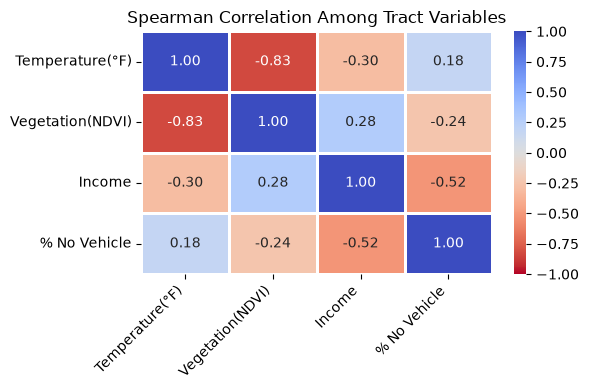

In [ ]:
#Q2
temp_list = tracts_analysis.select(['lst_f'])
ndvi_list = tracts_analysis.select(['ndvi'])

spearres, p = stats.spearmanr(temp, ndvi)
pearres = stats.pearsonr(temp, ndvi)
# print(spearres.statistic, spearres.pvalue)
# print(pearres.statistic, pearres.pvalue)

corr_table = tracts_analysis[['lst_f','ndvi','median_income','pct_no_vehicle']].corr(method='spearman')
corr_table = corr_table.rename(columns={
    'lst_f': 'Temperature(°F)',
    'ndvi': 'Vegetation(NDVI)',
    'median_income': 'Income',
    'pct_no_vehicle': '% No Vehicle'
}
)
corr_table = corr_table.rename(index={
    'lst_f': 'Temperature(°F)',
    'ndvi': 'Vegetation(NDVI)',
    'median_income': 'Income',
    'pct_no_vehicle': '% No Vehicle'
}
)
plt.figure(figsize=(6,4))
sns.heatmap(
    corr_table,
    annot=True,
    fmt='.2f',
    cmap='coolwarm_r',
    center= 0, vmin=-1,vmax=1,
    linewidths=1
)

plt.title('Spearman Correlation Among Tract Variables')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('data/figures/spearcorrelation.svg', dpi=300, bbox_inches='tight')



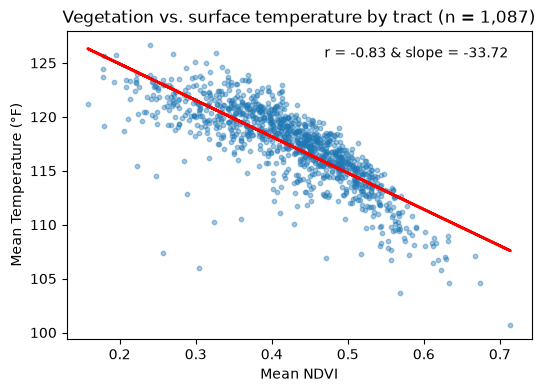

In [86]:
temp_list = tracts_analysis['lst_f']
ndvi_list = tracts_analysis['ndvi']
slope, intercept = np.polyfit(ndvi_list, temp_list, 1)

plt.figure(figsize=(6,4))
plt.scatter(ndvi_list, temp_list, s=10, alpha=0.4)
x_value = ndvi_list
y_value = slope * x_value + intercept
plt.plot(x_value,y_value, color='red', linewidth=2)
plt.title('Vegetation vs. surface temperature by tract (n = 1,087)')
plt.xlabel('Mean NDVI')
plt.ylabel('Mean Temperature (°F)')
plt.text(0.95,0.95, f'r = {spearres.statistic:.2f} & slope = {slope:.2f}',ha='right', va='top', transform=plt.gca().transAxes)
plt.savefig('data/figures/ndvi_temp_scatter.svg', dpi=300, bbox_inches='tight')
plt.show()

In [90]:
#Q3
top_10 = tracts_analysis.nlargest(10, 'hvi')
top_10 = top_10.select(['GEOID', 'lst_f', 'ndvi', 'pct_no_vehicle', 'median_income', 'hvi', 'nearest_station'])
top_10

,GEOID,lst_f,ndvi,pct_no_vehicle,median_income,hvi,nearest_station
900,48439105207,126.668202,0.239726,24.3,28885.0,0.975460,T&P STATION
898,48439105204,125.025029,0.313131,19.3,40354.0,0.942978,T&P STATION
896,48439105201,124.281118,0.341050,35.9,32986.0,0.941366,T&P STATION
763,48113016607,121.887163,0.267248,16.5,27037.0,0.917302,Westmoreland
899,48439105206,125.878298,0.327244,11.2,44435.0,0.911451,T&P STATION
907,48439105513,122.296370,0.317964,21.5,44773.0,0.910722,T&P STATION
742,48113016203,122.104747,0.289922,20.3,48846.0,0.908445,WEST IRVING STATION
908,48439105514,122.073222,0.270229,14.6,43333.0,0.907919,T&P STATION
792,48113017819,123.153177,0.221048,8.8,39158.0,0.906518,LAWNVIEW STATION
479,48439122300,120.725904,0.305579,22.9,27276.0,0.905368,Bell


## 11. Visualization

## 12. Exporting